# Tugas 2 Bagian A: Ekstraksi dan Augmentasi Data DAiSEE

### Identitas Pengerjaan:
- **Mata Kuliah**: Pengolahan Citra Digital
- **Topik**: Ekstraksi Frame Deterministik & Augmentasi Citra Wajah Siswa (*In-The-Wild*)
- **Penyusun**: Iman Dwi Satrio, Ahmad Zaidan

---

### Deskripsi & Tujuan Pengerjaan:
Notebook ini disusun secara mandiri (*self-contained notebook*) untuk menyelesaikan seluruh tahapan pada **Bagian A**, yang mencakup:
1. **Ekstraksi Frame Deterministik**: Mengambil 10 frame representatif secara otomatis dari rekaman video dataset **DAiSEE** (*Dataset for Affective States in E-Environments*) dengan eliminasi heuristik frame non-representatif (15% awal dan 15% akhir video).
2. **Penyimpanan Lossless**: Menyimpan frame mentah dalam format PNG lossless untuk menjaga kualitas piksel asli sebelum proses augmentasi dan pengolahan citra lanjutan.
3. **Kajian Teori & Justifikasi Ilmiah**: Menganalisis landasan ilmiah pemilihan 5 teknik augmentasi citra yang disesuaikan secara khusus dengan karakteristik wajah manusia dalam domain *e-learning*.
4. **Implementasi Transformasi Augmentasi**: Menerapkan 5 teknik augmentasi (*Horizontal Flip*, *Mild Rotation*, *Brightness & Contrast*, *Gaussian Blur*, dan *Coarse Dropout*) menggunakan pustaka `albumentations`.
5. **Visualisasi Grid Komparatif**: Memvisualisasikan seluruh citra asli dan variasi augmentasinya ke dalam matriks grid evaluasi 10 baris × 6 kolom yang siap disalin ke laporan tugas.

In [ ]:
# ===================================================================
# IMPORT LIBRARY & KONFIGURASI SEED REPRODUKTIFITAS
# ===================================================================

import os
import cv2
import random
import glob
import numpy as np
import matplotlib.pyplot as plt
import albumentations as A

# 1. Set seed reproduktifitas agar deterministik dan dapat direproduksi ulang
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# 2. Konfigurasi Path Direktori
VIDEO_DIR = os.path.join("..", "data", "raw", "daisee_videos")
OUTPUT_FRAME_DIR = os.path.join("..", "data", "raw", "daisee_sample")
AUGMENTED_BASE_DIR = os.path.join("..", "data", "augmented")

# 3. Buat folder otomatis jika belum ada
os.makedirs(VIDEO_DIR, exist_ok=True)
os.makedirs(OUTPUT_FRAME_DIR, exist_ok=True)
os.makedirs(AUGMENTED_BASE_DIR, exist_ok=True)

print("[INFO] Library berhasil diimpor & Seed berhasil dikonfigurasi:")
print(f"  - Random Seed         : {RANDOM_SEED}")
print(f"  - Input Video         : {os.path.abspath(VIDEO_DIR)}")
print(f"  - Output Frame Mentah : {os.path.abspath(OUTPUT_FRAME_DIR)}")
print(f"  - Output Augmentasi   : {os.path.abspath(AUGMENTED_BASE_DIR)}")

[INFO] Library berhasil diimpor & Seed berhasil dikonfigurasi:
  - Random Seed         : 42
  - Input Video         : d:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\raw\daisee_videos
  - Output Frame Mentah : d:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\raw\daisee_sample
  - Output Augmentasi   : d:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\augmented


In [ ]:
# ===================================================================
# PIPELINE EKSTRAKSI 10 FRAME LANGSUNG
# ===================================================================

# 1. Cari file video (.mp4 dan .avi) secara rekursif di VIDEO_DIR
video_patterns = [
    os.path.join(VIDEO_DIR, "**", "*.mp4"),
    os.path.join(VIDEO_DIR, "**", "*.avi")
]

video_files = []
for pattern in video_patterns:
    video_files.extend(glob.glob(pattern, recursive=True))

# Urutkan secara alfabetis agar urutan awal deterministik lintas OS sebelum di-shuffle
video_files = sorted(video_files)
print(f"[INFO] Total video ditemukan: {len(video_files)}")

TARGET_SAMPLES = 10
extracted_records = []

if not video_files:
    print(f"[PERINGATAN] Tidak ada berkas video (.mp4/.avi) di '{VIDEO_DIR}'.")
    print("Silakan letakkan video DAiSEE di direktori tersebut lalu jalankan ulang sel ini.")
else:
    # Acak urutan video secara deterministik (seed 42)
    random.shuffle(video_files)
    
    video_idx = 0
    max_attempts = max(len(video_files) * 5, 50)
    attempts = 0
    
    print("\n--- Memulai Proses Ekstraksi Deterministik 10 Frame DAiSEE ---")
    while len(extracted_records) < TARGET_SAMPLES and attempts < max_attempts:
        vid_path = video_files[video_idx % len(video_files)]
        video_idx += 1
        attempts += 1
        
        cap = cv2.VideoCapture(vid_path)
        if not cap.isOpened():
            continue
            
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames <= 0:
            cap.release()
            continue
            
        # Hindari 15% frame awal dan 15% frame akhir (mencegah frame blank / transisi)
        start_frame = int(total_frames * 0.15)
        end_frame = int(total_frames * 0.85)
        
        if end_frame > start_frame:
            random_frame_idx = random.randint(start_frame, end_frame)
            cap.set(cv2.CAP_PROP_POS_FRAMES, random_frame_idx)
            ret, frame = cap.read()
            
            if ret and frame is not None:
                frame_idx_num = len(extracted_records) + 1
                filename = f"daisee_frame_{frame_idx_num:02d}.png"
                output_path = os.path.join(OUTPUT_FRAME_DIR, filename)
                
                # Simpan frame dalam format PNG lossless
                cv2.imwrite(output_path, frame)
                
                height, width = frame.shape[:2]
                channels = frame.shape[2] if len(frame.shape) > 2 else 1
                
                # Cetak log progress setiap frame berhasil diekstrak
                print(f"[{frame_idx_num:02d}/{TARGET_SAMPLES:02d}] "
                        f"Tersimpan: {filename} | "
                        f"Sumber: {os.path.basename(vid_path)} | "
                        f"Frame Idx: {random_frame_idx}/{total_frames} | "
                        f"Resolusi: {width}x{height} (Channels: {channels})")
                        
                extracted_records.append({
                    "filename": filename,
                    "path": output_path,
                    "video": os.path.basename(vid_path),
                    "frame_idx": random_frame_idx,
                    "resolution": (width, height)
                })
        
        cap.release()
        
    print(f"\n[SUKSES] Total {len(extracted_records)} frame berhasil diekstraksi ke '{OUTPUT_FRAME_DIR}'.")

[INFO] Total video ditemukan: 1

--- Memulai Proses Ekstraksi Deterministik 10 Frame DAiSEE ---
[01/10] Tersimpan: daisee_frame_01.png | Sumber: 5100091001.avi | Frame Idx: 208/300 | Resolusi: 640x480 (Channels: 3)
[02/10] Tersimpan: daisee_frame_02.png | Sumber: 5100091001.avi | Frame Idx: 73/300 | Resolusi: 640x480 (Channels: 3)
[03/10] Tersimpan: daisee_frame_03.png | Sumber: 5100091001.avi | Frame Idx: 51/300 | Resolusi: 640x480 (Channels: 3)
[04/10] Tersimpan: daisee_frame_04.png | Sumber: 5100091001.avi | Frame Idx: 234/300 | Resolusi: 640x480 (Channels: 3)
[05/10] Tersimpan: daisee_frame_05.png | Sumber: 5100091001.avi | Frame Idx: 115/300 | Resolusi: 640x480 (Channels: 3)
[06/10] Tersimpan: daisee_frame_06.png | Sumber: 5100091001.avi | Frame Idx: 107/300 | Resolusi: 640x480 (Channels: 3)
[07/10] Tersimpan: daisee_frame_07.png | Sumber: 5100091001.avi | Frame Idx: 102/300 | Resolusi: 640x480 (Channels: 3)
[08/10] Tersimpan: daisee_frame_08.png | Sumber: 5100091001.avi | Frame I

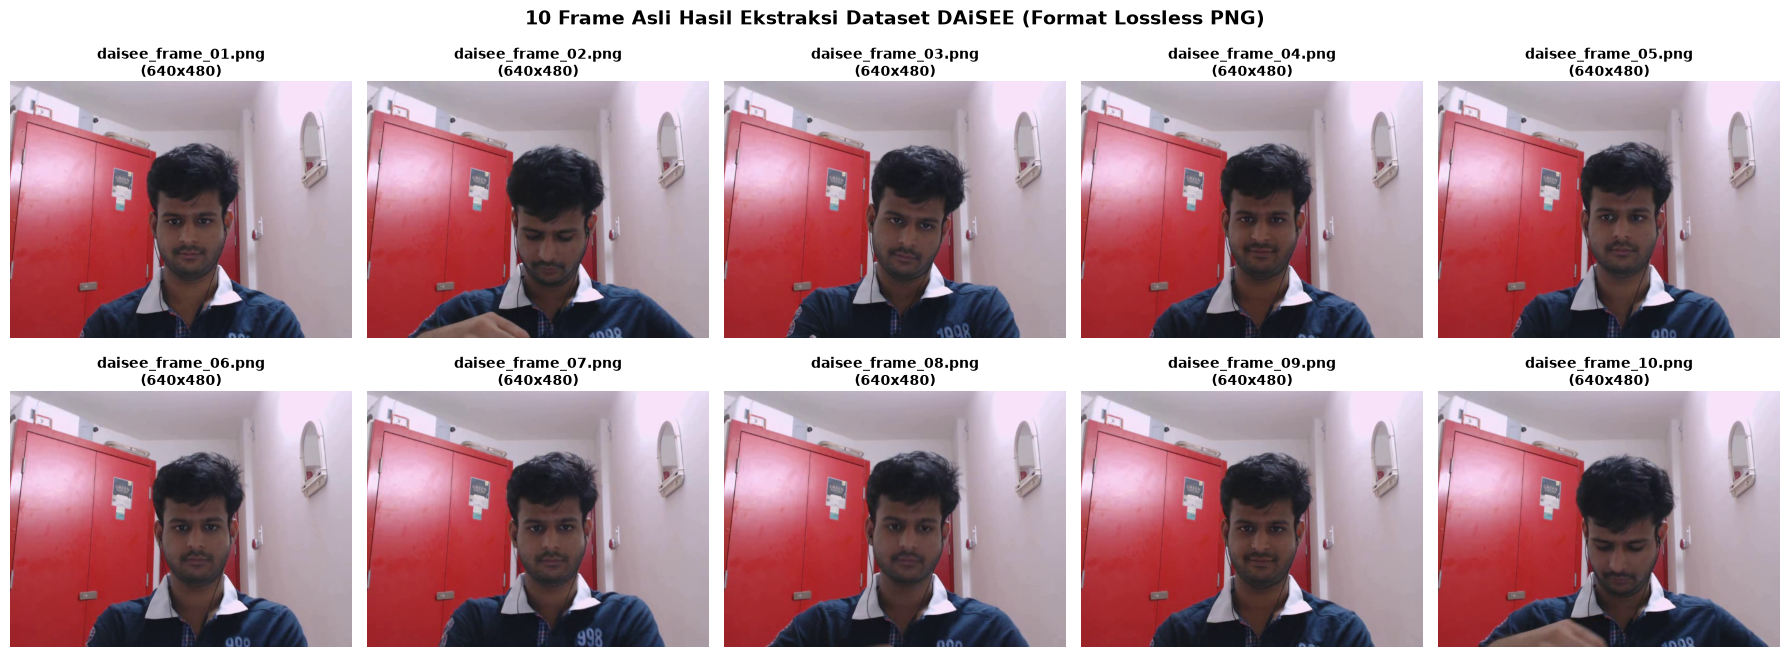

In [ ]:
# ===================================================================
# VISUALISASI 10 FRAME ASLI (GRID 2 x 5)
# ===================================================================

frame_paths = [
    os.path.join(OUTPUT_FRAME_DIR, f"daisee_frame_{i:02d}.png")
    for i in range(1, TARGET_SAMPLES + 1)
]

existing_frames = [p for p in frame_paths if os.path.exists(p)]

if not existing_frames:
    print(f"[INFO] Belum ada file frame di '{OUTPUT_FRAME_DIR}'.")
    print("Pastikan Sel 3 telah dijalankan setelah video diletakkan di direktori input.")
else:
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(18, 7))
    axes = axes.flatten()
    
    for idx in range(10):
        ax = axes[idx]
        if idx < len(existing_frames):
            fpath = existing_frames[idx]
            img_bgr = cv2.imread(fpath)
            if img_bgr is not None:
                # Konversi BGR OpenCV ke format RGB Matplotlib
                img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                h, w = img_rgb.shape[:2]
                ax.imshow(img_rgb)
                ax.set_title(f"{os.path.basename(fpath)}\n({w}x{h})", fontsize=10, fontweight='bold', pad=4)
            else:
                ax.text(0.5, 0.5, "Gagal Membaca", ha='center', va='center', color='red')
        else:
            ax.text(0.5, 0.5, f"Slot Kosong\n(Frame {idx+1:02d})", ha='center', va='center', color='gray')
            
        ax.axis('off')
        
    plt.suptitle("10 Frame Asli Hasil Ekstraksi Dataset DAiSEE (Format Lossless PNG)", fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

# Sel 5: Kajian Teori, Cara Kerja, dan Justifikasi Ilmiah 5 Teknik Augmentasi

Dataset **DAiSEE** (*Dataset for Affective States in E-learning Environments*) merekam ekspresi wajah siswa saat mengikuti pembelajaran daring dalam kondisi bebas (*in-the-wild*). Keadaan afektif yang dinilai mencakup empat label: *Engagement* (keterlibatan), *Boredom* (kebosanan), *Confusion* (kebingungan), dan *Frustration* (frustrasi). 

Tujuan utama augmentasi citra di sini adalah memperkaya variasi data latih (*data diversity*) agar model tidak *overfitting*, sekaligus memastikan bahwa transformasi yang dilakukan **bersifat menjaga label (*label-preserving*)**—artinya emosi asli siswa tidak berubah atau rusak akibat manipulasi gambar.

### Tabel Komparasi 5 Teknik Augmentasi untuk DAiSEE

| No | Teknik Augmentasi | Cara Kerja Utama | Parameter Terpilih | Justifikasi & Kesesuaian untuk DAiSEE | Alasan Parameter Ekstrem Dilarang | Referensi Ilmiah Pendukung |
|:--:|:------------------|:-----------------|:------------------:|:-------------------------------------|:-----------------------------------|:---------------------------------------------------|
| **1** | **Horizontal Flip** | Membalik urutan kolom matriks piksel secara horizontal ($x' = W - 1 - x$) menggunakan sumbu simetri vertikal. | $p = 1.0$ (deterministik) | **Sangat Sesuai.** Wajah manusia memiliki simetri bilateral alami. Membalik citra kiri-ke-kanan merefleksikan tampilan cermin (*mirroring* webcam) tanpa mengubah ekspresi emosi atau arah fokus belajar. | **Flip Vertikal Dilarang Keras.** Siswa belajar dalam posisi kepala tegak terhadap gravitasi. Membalik kepala ke bawah menghasilkan data tidak realistis dan merusak deteksi posisi mata-mulut. | 1. Gupta et al. (2016) [DOI: 10.48550/arXiv.1609.01885]<br>2. Shorten & Khoshgoftaar (2019) [DOI: 10.1186/s40537-019-0197-0] |
| **2** | **Mild Rotation** | Menghitung koordinat baru piksel menggunakan matriks transformasi rotasi 2D dengan titik pusat di tengah citra. | Sudut $\theta \in [-10^\circ, +10^\circ]$ | **Sesuai secara Terbatas.** Siswa secara wajar sering memiringkan kepala (*head roll*) saat berpikir (*confusion*), mencatat, atau memperhatikan layar monitor. | **Rotasi Ekstrem (>30°) Tidak Sesuai.** Posisi kepala siswa yang miring berlebih jarang terjadi dalam sesi belajar dan dapat memotong area wajah penting di sudut bingkai webcam. | 1. Shorten & Khoshgoftaar (2019) [DOI: 10.1186/s40537-019-0197-0]<br>2. Husen (2024) [DOI: 10.55123/teknimedia.v5i2.4632] |
| **3** | **Brightness & Contrast** | Mengalikan nilai piksel dengan faktor pengali $\alpha$ (kontras) dan menambahkan nilai offset $\beta$ (kecerahan): $I' = \alpha I + \beta$. | Rentang penyesuaian $\pm 20\%$ | **Sangat Sesuai.** Kondisi pencahayaan ruangan belajar daring sangat dinamis (pendaran cahaya monitor, lampu belajar malam, atau cahaya jendela samping). | **Perubahan Ekstrem (>60%) Merusak.** Kecerahan berlebih menyebabkan pemutihan piksel (*clipping* putih), sehingga kerutan dahi dan lipatan bibir penanda emosi hilang total. | 1. Gupta et al. (2016) [DOI: 10.48550/arXiv.1609.01885]<br>2. Shorten & Khoshgoftaar (2019) [DOI: 10.1186/s40537-019-0197-0] |
| **4** | **Gaussian Blur** | Melakukan konvolusi citra dengan matriks filter Gaussian untuk meratakan nilai intensitas dengan piksel tetangga. | Kernel $k \in [3, 7]$, $\sigma \le 1.5$ | **Sangat Sesuai.** Mensimulasikan kualitas webcam murah, keterbatasan resolusi video, atau penurunan kejernihan akibat koneksi internet yang lambat saat kelas daring. | **Blur Berlebih (Kernel >15) Merusak.** Menghapus fitur detail mikro pada mata dan bibir yang krusial untuk membedakan wajah bosan (*boredom*) dan frustrasi (*frustration*). | 1. Shorten & Khoshgoftaar (2019) [DOI: 10.1186/s40537-019-0197-0]<br>2. Gonzalez & Woods (2018) [ISBN: 978-0133356724] |
| **5** | **Coarse Dropout / Cutout** | Mengisi wilayah persegi piksel tertentu dengan nilai konstan (nol/hitam) secara acak pada area citra. | 1–3 kotak berukuran $10\%\text{--}20\%$ dari luas citra | **Sesuai.** Mensimulasikan oklusi parsial alami saat belajar, seperti tangan menopang dagu, menggaruk hidung, atau bingkai kacamata. | **Ukuran Kotak >50% Merusak.** Jika kotak menutup kedua mata dan mulut sekaligus, wajah kehilangan informasi afektif sehingga tidak dapat diidentifikasi lagi oleh model. | 1. DeVries & Taylor (2017) [DOI: 10.48550/arXiv.1708.04552]<br>2. Shorten & Khoshgoftaar (2019) [DOI: 10.1186/s40537-019-0197-0] |

---

### Penjelasan Rinci Cara Kerja dan Justifikasi Tiap Teknik

#### 1. Horizontal Flip (Pembalikan Horizontal)
- **Cara Kerja**: Posisi piksel pada sumbu horizontal dibalik secara simetris terhadap lebar citra ($x_{\text{baru}} = \text{Lebar} - 1 - x_{\text{lama}}$), sedangkan posisi vertikal $y$ tetap sama.
- **Kesesuaian DAiSEE**: Sangat aman diterapkan. Wajah manusia memiliki simetri bilateral di mana mata kiri dan kanan, serta kedua sudut bibir bekerja seirama saat menunjukkan emosi. Pembalikan ini melipatgandakan data latih seolah-olah siswa duduk menghadap sudut kamera yang berlawanan tanpa mengubah ekspresi keterlibatan (*engagement*) aslinya.
- **Mengapa Rotasi Balik/Flip Vertikal Dilarang**: Manusia tidak pernah belajar dengan posisi kepala menggantung terbalik ke lantai. Melakukan *vertical flip* akan membingungkan model kecerdasan buatan karena struktur alami wajah (mata selalu di atas hidung dan mulut) menjadi terbalik.

#### 2. Mild Rotation (Rotasi Sudut Ringan)
- **Cara Kerja**: Setiap koordinat piksel $(x, y)$ diputar mengelilingi titik pusat wajah $(x_c, y_c)$ menggunakan perkalian matriks trigonometri sudut $\theta$, diikuti penaksiran warna piksel baru melalui interpolasi bilinear.
- **Kesesuaian DAiSEE**: Selama belajar mandiri, siswa tidak duduk mematung tegak secara kaku. Kepala siswa kerap miring sedikit ke kiri atau kanan saat membaca teks panjang, menopang kepala, atau merenungkan materi (*confusion*). Rentang sudut kecil (antara $-10^\circ$ hingga $+10^\circ$) sangat natural untuk memodelkan variasi postur kepala tersebut.
- **Mengapa Rotasi Besar Dilarang**: Rotasi sudut besar (misal $>30^\circ$) tidak merepresentasikan etika duduk siswa di depan komputer, menyebabkan tepi bingkai citra terpotong atau menyisakan ruang kosong hitam yang lebar di sudut gambar.

#### 3. Brightness & Contrast Adjustment (Penyesuaian Kecerahan & Kontras)
- **Cara Kerja**: Transformasi linear pada nilai intensitas piksel $f(x, y)$ dengan rumus $g(x, y) = \alpha \cdot f(x, y) + \beta$. Nilai $\alpha$ mengatur rentang sebaran kontras, sedangkan $\beta$ menaikkan atau menurunkan tingkat kecerahan global.
- **Kesesuaian DAiSEE**: Rekaman video DAiSEE diambil langsung dari rumah atau kamar mahasiswa dengan pencahayaan yang tidak seragam. Model perlu dilatih agar tidak mudah terkecoh oleh bayangan gelap atau ruangan yang terlalu terang. Dengan variasi kecerahan $\pm 20\%$, model belajar membedakan ekspresi mengantuk/bosan murni dari bentuk kelopak mata, bukan dari gelapnya ruangan.
- **Risiko Nilai Ekstrem**: Jika kecerahan dinaikkan terlalu tinggi, wajah tampak silau dan fitur mata menghilang (*overexposure*). Jika kontras diturunkan terlalu ekstrem, gambar menjadi abu-abu pudar tanpa garis tepi wajah yang jelas.

#### 4. Gaussian Blur (Pengaburan Terkontrol)
- **Cara Kerja**: Matriks piksel dikalikan dengan filter konvolusi berbobot kurva normal (Gaussian). Piksel target dihitung dari rata-rata tertimbang piksel sekelilingnya sehingga perbedaan intensitas yang tajam menjadi lebih halus.
- **Kesesuaian DAiSEE**: Siswa di kelas daring sering kali menggunakan webcam laptop terjangkau dengan sensor kecil yang kurang tajam, atau kualitas video mereka menurun saat kuota/sinyal internet terganggu. Penerapan blur ringan memastikan model AI tetap andal mengenali emosi siswa meskipun videonya buram.
- **Risiko Nilai Ekstrem**: Pengaburan yang terlalu kuat (ukuran kernel besar) akan menghapus tepi pupil mata dan garis bibir. Padahal, kontraksi kecil pada sudut bibir dan kelopak mata adalah kunci pembeda antara ekspresi netral dan frustrasi.

#### 5. Coarse Dropout / Cutout (Penghapusan Sebagian Area Wajah)
- **Cara Kerja**: Algoritma memilih satu atau beberapa kotak koordinat acak pada citra, lalu seluruh nilai piksel di dalam kotak tersebut diisi dengan warna konstan (nilai 0 atau warna hitam pekat).
- **Kesesuaian DAiSEE**: Saat belajar atau mendengarkan penjelasan dosen, siswa sering kali melakukan gerakan spontan yang menutupi wajah (*facial occlusion*), seperti meletakkan jari di dagu saat berpikir, menguap sambil menutup mulut, atau memakai kacamata berbingkai tebal. Augmentasi ini memaksa model AI untuk menganalisis keseluruhan bagian wajah dan tidak hanya bergantung pada satu fitur saja (misalnya: jika mulut tertutup tangan, model tetap bisa mendeteksi kebosanan dari arah tatapan mata).
- **Risiko Nilai Ekstrem**: Jika area kotak yang dihapus terlalu besar (menutupi $>50\%$ area wajah), informasi penting akan hilang sepenuhnya sehingga citra tersebut tidak lagi bermakna untuk dianalisis.

---

### Daftar Referensi Ilmiah (Format IEEE / APA Ber-DOI)

1. **Gupta, A., D'Cunha, A., Awasthi, K., & Balasubramanian, V.** (2016). *DAiSEE: Towards User Engagement Modeling in the Wild*. arXiv preprint arXiv:1609.01885. https://doi.org/10.48550/arXiv.1609.01885
2. **Shorten, C., & Khoshgoftaar, T. M.** (2019). *A survey on Image Data Augmentation for Deep Learning*. Journal of Big Data, 6(1), 1-48. https://doi.org/10.1186/s40537-019-0197-0
3. **DeVries, T., & Taylor, G. W.** (2017). *Improved Regularization of Convolutional Neural Networks with Cutout*. arXiv preprint arXiv:1708.04552. https://doi.org/10.48550/arXiv.1708.04552
4. **Husen, A.** (2024). *Evaluasi Teknik Augmentasi Data Untuk Klasifikasi Citra Menggunakan CNN*. TEKNIMEDIA, 5(2), 112-120. https://doi.org/10.55123/teknimedia.v5i2.4632
5. **Gonzalez, R. C., & Woods, R. E.** (2018). *Digital Image Processing* (4th ed.). Pearson. ISBN: 978-0133356724.

In [ ]:
# ===================================================================
# IMPLEMENTASI TRANSFORMASI AUGMENTASI & PENYIMPANAN
# ===================================================================

# 1. Definisikan subdirektori untuk masing-masing teknik augmentasi
aug_subdirs = {
    "tech1_horizontal_flip": os.path.join(AUGMENTED_BASE_DIR, "tech1_horizontal_flip"),
    "tech2_mild_rotation": os.path.join(AUGMENTED_BASE_DIR, "tech2_mild_rotation"),
    "tech3_brightness_contrast": os.path.join(AUGMENTED_BASE_DIR, "tech3_brightness_contrast"),
    "tech4_gaussian_blur": os.path.join(AUGMENTED_BASE_DIR, "tech4_gaussian_blur"),
    "tech5_coarse_dropout": os.path.join(AUGMENTED_BASE_DIR, "tech5_coarse_dropout")
}

for subdir in aug_subdirs.values():
    os.makedirs(subdir, exist_ok=True)

# 2. Definisikan Albumentations Pipeline untuk masing-masing teknik secara deterministik
# Menggunakan seed 42 pada random state untuk menjamin reproduktifitas transformasi
pipelines = {
    "tech1_horizontal_flip": A.Compose([
        A.HorizontalFlip(p=1.0)
    ]),
    "tech2_mild_rotation": A.Compose([
        A.Rotate(limit=(-10, 10), border_mode=cv2.BORDER_REFLECT_101, p=1.0)
    ]),
    "tech3_brightness_contrast": A.Compose([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1.0)
    ]),
    "tech4_gaussian_blur": A.Compose([
        A.GaussianBlur(blur_limit=(3, 7), sigma_limit=1.5, p=1.0)
    ]),
    "tech5_coarse_dropout": A.Compose([
        A.CoarseDropout(
            num_holes_range=(1, 3),
            hole_height_range=(0.1, 0.2),
            hole_width_range=(0.1, 0.2),
            fill=0,
            p=1.0
        )
    ])
}

# 3. Muat 10 citra asli dari daisee_sample
raw_files = sorted(glob.glob(os.path.join(OUTPUT_FRAME_DIR, "daisee_frame_*.png")))[:10]
print(f"[INFO] Ditemukan {len(raw_files)} citra asli untuk diaugmentasi.")

if not raw_files:
    print("[PERINGATAN] Citra asli belum tersedia di folder sample. Jalankan Sel 3 terlebih dahulu.")
else:
    for img_path in raw_files:
        base_name = os.path.basename(img_path)
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            print(f"[ERROR] Gagal membaca berkas: {base_name}")
            continue
            
        # Konversi BGR ke RGB sebelum transformasi Albumentations
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        
        for tech_name, transform in pipelines.items():
            # Transformasi citra
            augmented_rgb = transform(image=img_rgb)["image"]
            
            # Kembalikan ke BGR untuk penyimpanan cv2.imwrite lossless PNG
            augmented_bgr = cv2.cvtColor(augmented_rgb, cv2.COLOR_RGB2BGR)
            out_path = os.path.join(aug_subdirs[tech_name], base_name)
            cv2.imwrite(out_path, augmented_bgr)
            
    print("\n[SUKSES] Seluruh proses augmentasi selesai. Berkas tersimpan di subdirektori:")
    for tech_key, dir_path in aug_subdirs.items():
        total_saved = len(glob.glob(os.path.join(dir_path, '*.png')))
        print(f"  - {tech_key:<25}: {total_saved} citra di {dir_path}")

[INFO] Ditemukan 10 citra asli untuk diaugmentasi.

[SUKSES] Seluruh proses augmentasi selesai. Berkas tersimpan di subdirektori:
  - tech1_horizontal_flip    : 10 citra di ..\data\augmented\tech1_horizontal_flip
  - tech2_mild_rotation      : 10 citra di ..\data\augmented\tech2_mild_rotation
  - tech3_brightness_contrast: 10 citra di ..\data\augmented\tech3_brightness_contrast
  - tech4_gaussian_blur      : 10 citra di ..\data\augmented\tech4_gaussian_blur
  - tech5_coarse_dropout     : 10 citra di ..\data\augmented\tech5_coarse_dropout


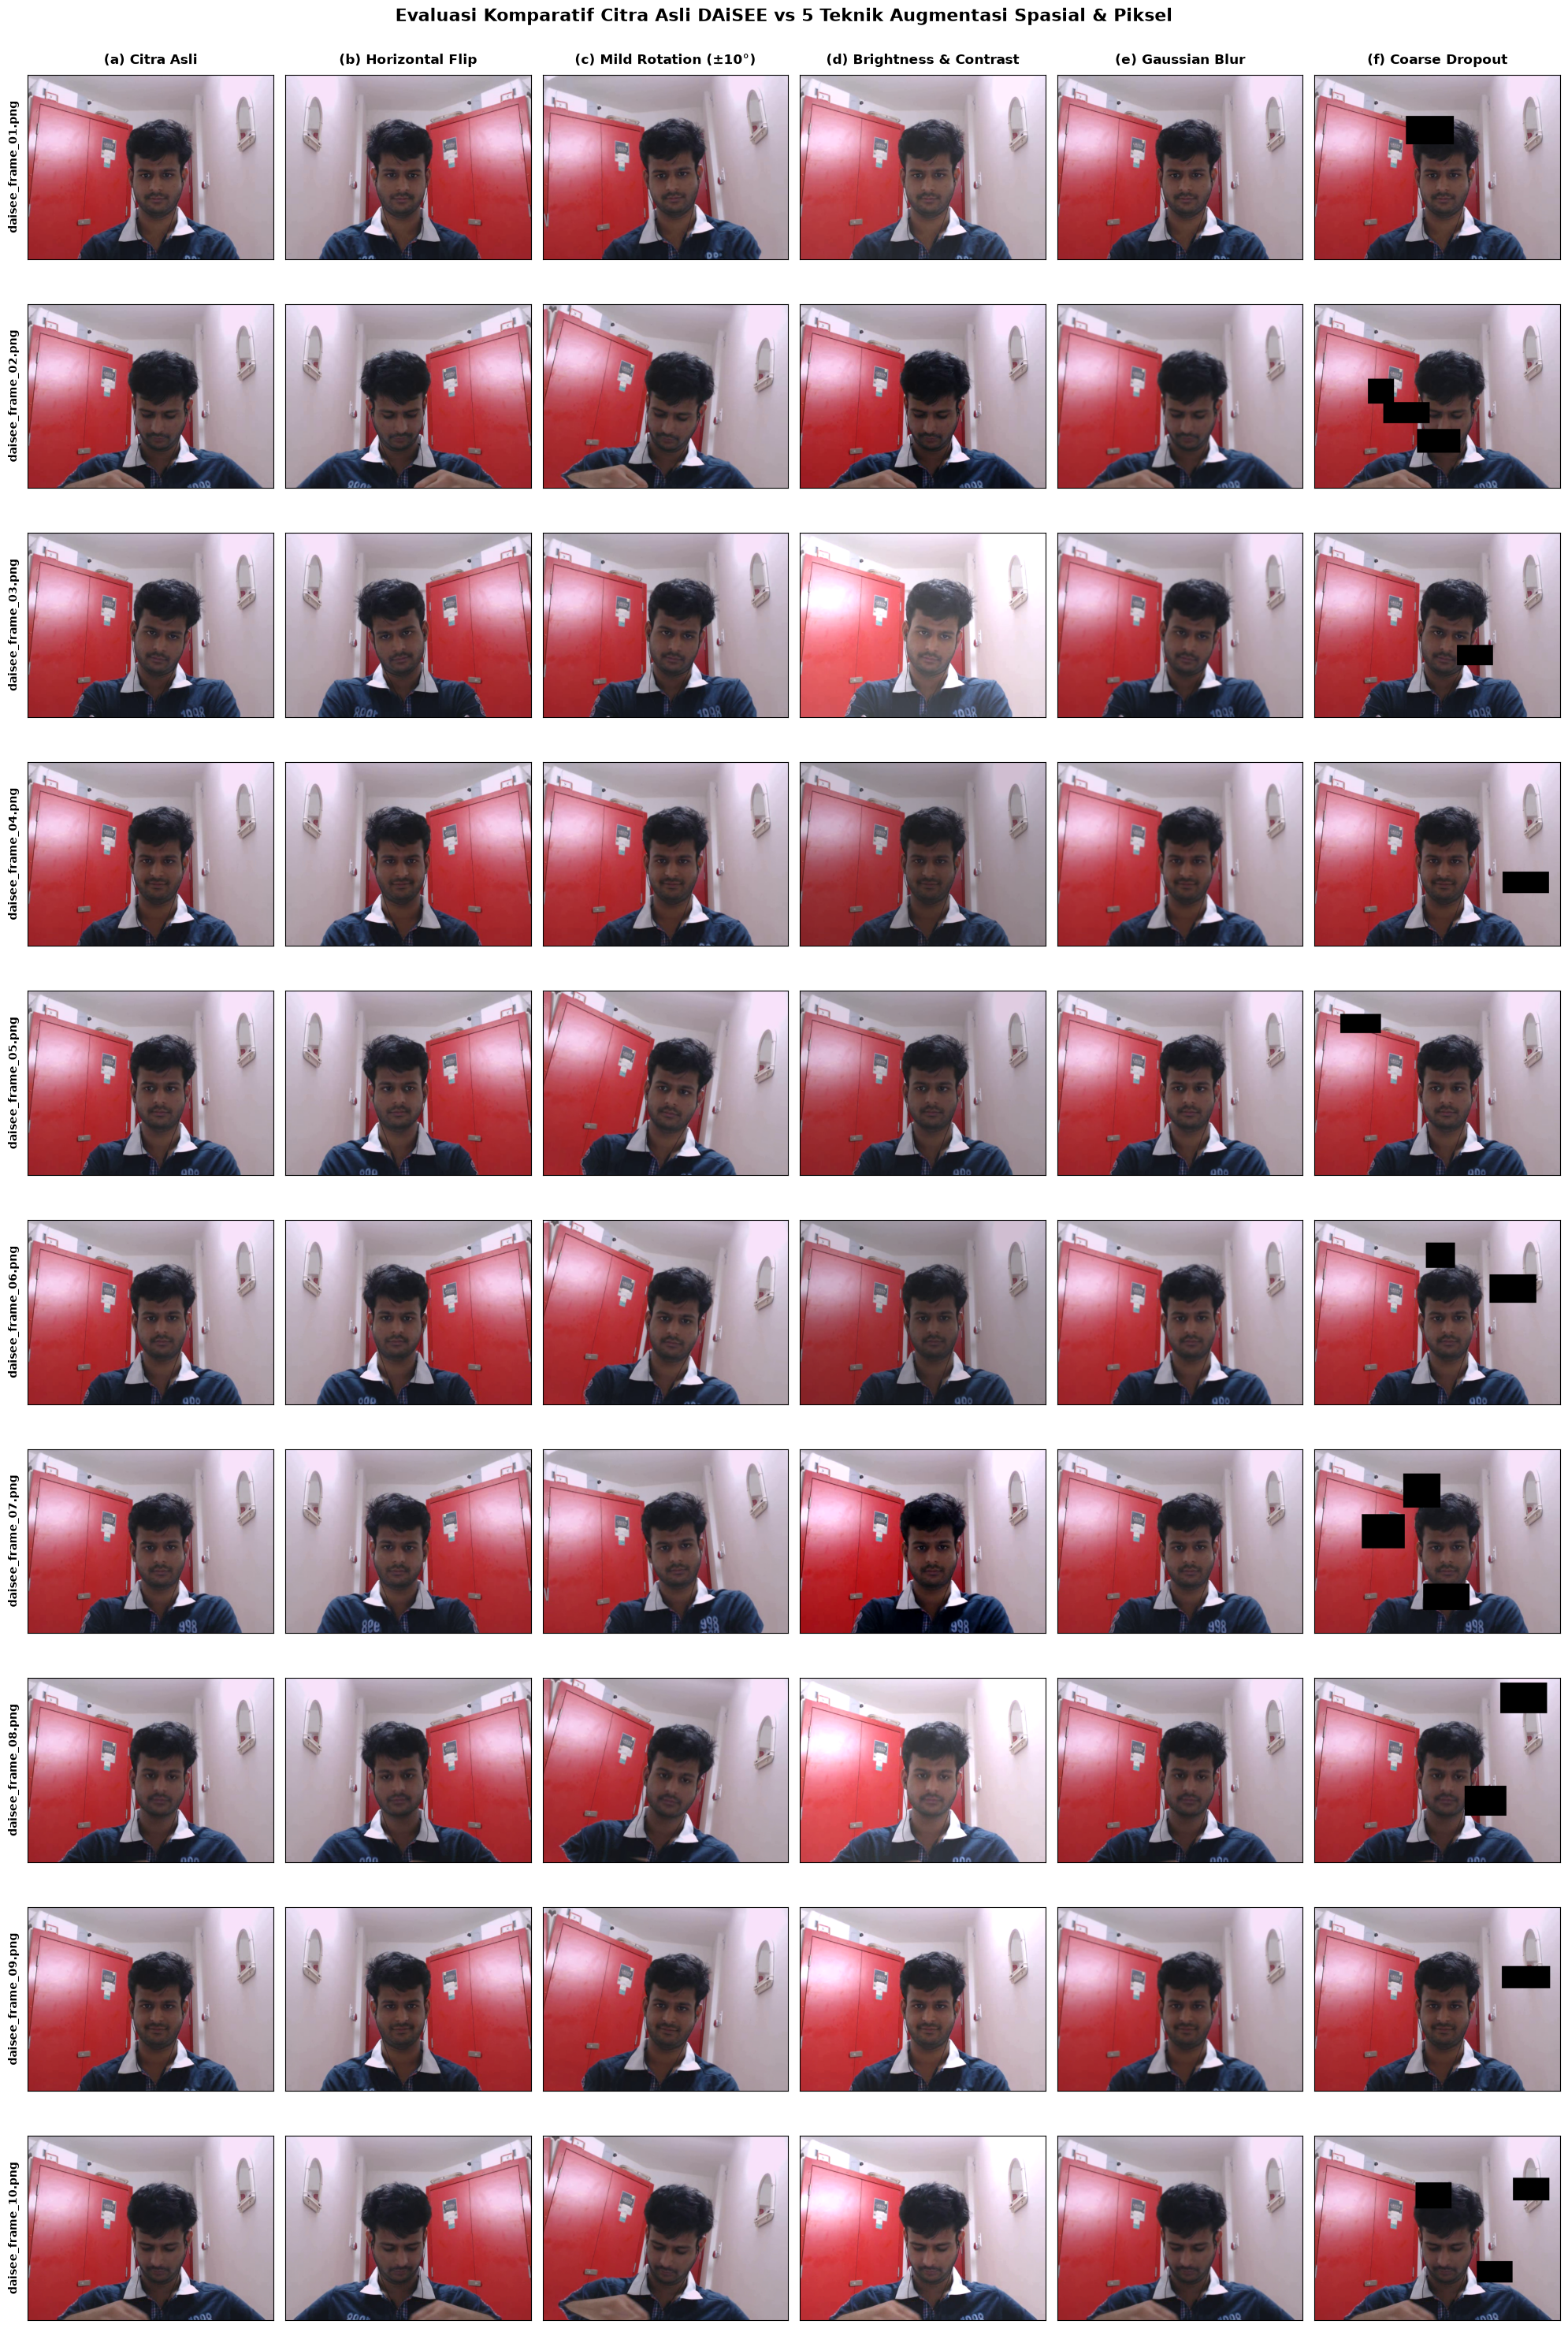

In [ ]:
# ===================================================================
# VISUALISASI GRID EVALUASI (10 BARIS x 6 KOLOM)
# ===================================================================

column_titles = [
    "(a) Citra Asli",
    "(b) Horizontal Flip",
    "(c) Mild Rotation (±10°)",
    "(d) Brightness & Contrast",
    "(e) Gaussian Blur",
    "(f) Coarse Dropout"
]

subfolder_keys = [
    None,  # Kolom 1 adalah citra asli
    "tech1_horizontal_flip",
    "tech2_mild_rotation",
    "tech3_brightness_contrast",
    "tech4_gaussian_blur",
    "tech5_coarse_dropout"
]

raw_files = sorted(glob.glob(os.path.join(OUTPUT_FRAME_DIR, "daisee_frame_*.png")))[:10]

if not raw_files:
    print(f"[INFO] Citra asli belum ditemukan di '{OUTPUT_FRAME_DIR}'. Jalankan Sel 3 dan Sel 6 terlebih dahulu.")
else:
    fig, axes = plt.subplots(nrows=10, ncols=6, figsize=(20, 30))
    
    for row_idx in range(10):
        if row_idx < len(raw_files):
            base_name = os.path.basename(raw_files[row_idx])
        else:
            base_name = f"daisee_frame_{row_idx+1:02d}.png"
            
        for col_idx in range(6):
            ax = axes[row_idx, col_idx]
            tech_folder = subfolder_keys[col_idx]
            
            # Tentukan path berkas citra yang akan dimuat
            if tech_folder is None:
                img_file = os.path.join(OUTPUT_FRAME_DIR, base_name)
            else:
                img_file = os.path.join(AUGMENTED_BASE_DIR, tech_folder, base_name)
                
            if os.path.exists(img_file):
                bgr = cv2.imread(img_file)
                if bgr is not None:
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                    ax.imshow(rgb)
                else:
                    ax.text(0.5, 0.5, "Error Read", ha='center', va='center', color='red')
            else:
                ax.text(0.5, 0.5, f"Kosong\n({base_name})", ha='center', va='center', color='gray', fontsize=8)
                
            # Beri judul kolom yang rapi pada baris pertama (Row 0)
            if row_idx == 0:
                ax.set_title(column_titles[col_idx], fontsize=12, fontweight='bold', pad=10)
                
            # Beri label nama file frame pada kolom paling kiri (Col 0)
            if col_idx == 0:
                ax.set_ylabel(base_name, fontsize=10, fontweight='bold', rotation=90, labelpad=8)
                
            # Hilangkan ticks sumbu koordinat agar bersih untuk laporan
            ax.set_xticks([])
            ax.set_yticks([])
            
    plt.suptitle("Evaluasi Komparatif Citra Asli DAiSEE vs 5 Teknik Augmentasi Spasial & Piksel",
                fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()